# PlantVillage Leaf Disease Classification – MLOps Assignment

**Objective:** Build an end-to-end image-classification workflow to identify plant crop-disease categories from leaf images, then develop retraining, API, UI, deployment, and monitoring components.

**Working plan:** Explore and inspect data locally. Move GPU-intensive training to Google Colab when needed. Each code section is introduced by a Markdown explanation. Run cells in order, share outputs, and interpret findings before making data or modelling decisions.

**Dataset facts recorded so far:** 43,596 training images, 10,709 testing images, 38 combined crop-disease classes, 14 crop types, and 21 disease names (including `healthy`).

## Notebook roadmap

1. Load the locally saved PlantVillage dataset and inspect its structure.
2. Analyze class distribution and important metadata.
3. Visually explore the images and interpret dataset features.
4. Investigate data quality: readability, exact duplicates, and `leaf_id` overlap.
5. Clean the evaluation data, create group-aware training/validation splits, and standardize images.
6. Validate the final datasets and document preparation decisions.

**Status:** Data understanding and preparation are complete. The next notebook will cover baseline model development, training, and evaluation.


## 0.1 Import all libraries used in the current notebook

We keep imports in the first code cell, as requested. These libraries support local dataset loading, numerical and tabular analysis, visualization, image inspection, hashing, and notebook display. We will add framework-specific libraries (for example TensorFlow or PyTorch) when we reach model development and decide which framework to use.

In [1]:
import os
import random
import hashlib
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, UnidentifiedImageError
from datasets import load_from_disk
from IPython.display import display

from sklearn.model_selection import StratifiedGroupKFold

from datasets import DatasetDict
from pathlib import Path
import json
import zipfile
import shutil

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Libraries imported successfully.")

Libraries imported successfully.


## 0.2 Load the locally saved dataset

This cell assumes the dataset was saved in Hugging Face Datasets format using `save_to_disk()`. Change `DATASET_DIR` to the actual local folder. Loading from disk avoids downloading the dataset again, which is useful when internet access is unstable. The loaded object must contain `train` and `test` splits, which we assign to `train_data` and `test_data` for use throughout the notebook.

In [2]:
DATASET_DIR = "../data/plantvillage"

dataset = load_from_disk(DATASET_DIR)
print(dataset)

train_data = dataset["train"]
test_data = dataset["test"]

print("Training images:", len(train_data))
print("Testing images:", len(test_data))

DatasetDict({
    train: Dataset({
        features: ['image', 'image_path', 'label', 'crop', 'disease', 'leaf_id'],
        num_rows: 43596
    })
    test: Dataset({
        features: ['image', 'image_path', 'label', 'crop', 'disease', 'leaf_id'],
        num_rows: 10709
    })
})
Training images: 43596
Testing images: 10709


## 1.1 Inspect dataset features and metadata

We inspect the schema to understand what information is available for every example. `image` contains the image, `label` is the encoded classification target, and `crop`, `disease`, and `leaf_id` are metadata useful for exploration and quality checks. The image will be the model input and the combined crop-disease `label` will be the prediction target. We should not pass metadata as hidden shortcuts to an image-only model.

In [3]:
print("Available dataset features:")
print(train_data.features)

print("\\nUnique crops:", len(set(train_data["crop"])))
print("Unique disease names:", len(set(train_data["disease"])))
print("Crop categories:", sorted(set(train_data["crop"])))
print("Disease categories:", sorted(set(train_data["disease"])))

class_names = train_data.features["label"].names
print("Number of classification classes:", len(class_names))

Available dataset features:
{'image': Image(mode=None, decode=True, id=None), 'image_path': Value(dtype='string', id=None), 'label': ClassLabel(names=['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blig

## 1.2 Analyze classification class distribution

We count the number of training images in each of the 38 combined crop-disease classes and calculate each class's percentage of the training set. We also identify the most and least represented classes and calculate the imbalance ratio (largest class count divided by smallest non-zero class count). This helps us understand whether some classes may be underrepresented during training. A rare class should not automatically be removed: doing so would make the model unable to predict it. We will later consider targeted augmentation, class weights, and per-class evaluation.

In [4]:
label_counts = Counter(train_data["label"])

class_distribution = pd.DataFrame({
    "Class ID": range(len(class_names)),
    "Class Name": class_names,
    "Number of Images": [label_counts.get(i, 0) for i in range(len(class_names))]
})
class_distribution["Percentage (%)"] = (
    class_distribution["Number of Images"] / len(train_data) * 100
).round(2)
class_distribution = class_distribution.sort_values(
    "Number of Images", ascending=False
).reset_index(drop=True)

display(class_distribution)

print("Most represented class:")
display(class_distribution.iloc[0])
print("Least represented class:")
display(class_distribution.iloc[-1])

counts = class_distribution["Number of Images"]
print("Class imbalance ratio:", round(counts.max() / counts[counts > 0].min(), 2))

,Class ID,Class Name,Number of Images,Percentage (%)
0,15,Orange___Haunglongbing_(Citrus_greening),4527,10.38
1,35,Tomato___Tomato_Yellow_Leaf_Curl_Virus,4257,9.76
2,24,Soybean___healthy,4117,9.44
3,16,Peach___Bacterial_spot,1755,4.03
4,28,Tomato___Bacterial_spot,1691,3.88
5,30,Tomato___Late_blight,1534,3.52
6,25,Squash___Powdery_mildew,1457,3.34
7,32,Tomato___Septoria_leaf_spot,1434,3.29
8,3,Apple___healthy,1359,3.12
9,33,Tomato___Spider_mites Two-spotted_spider_mite,1356,3.11


Most represented class:


Class ID                                                  15
Class Name          Orange___Haunglongbing_(Citrus_greening)
Number of Images                                        4527
Percentage (%)                                         10.38
Name: 0, dtype: object

Least represented class:


Class ID                          22
Class Name          Potato___healthy
Number of Images                 120
Percentage (%)                  0.28
Name: 37, dtype: object

Class imbalance ratio: 37.72



The training set contains 38 combined crop-disease classes. The most represented class is `Orange___Haunglongbing_(Citrus_greening)` with 4,527 images (10.38%), while the least represented class is `Potato___healthy` with 120 images (0.28%). The largest-to-smallest class ratio is approximately 37.72.

This imbalance matters because common classes may appear more often during training, while rare classes may be harder to learn. Overall accuracy could hide poor performance on minority classes. We should not remove rare classes simply because they have fewer examples: that would narrow the task and prevent the model from predicting those categories. Instead, we will investigate targeted augmentation and class-weighted training, and report per-class precision, recall, and F1-score.

## 1.3 Visualize the 38-class distribution

The table provides exact counts, while a sorted horizontal bar chart makes the differences easier to compare. We plot every class so that rare categories remain visible. This chart describes the number of examples available; it does not tell us how difficult a class is or how accurately a future model will classify it.

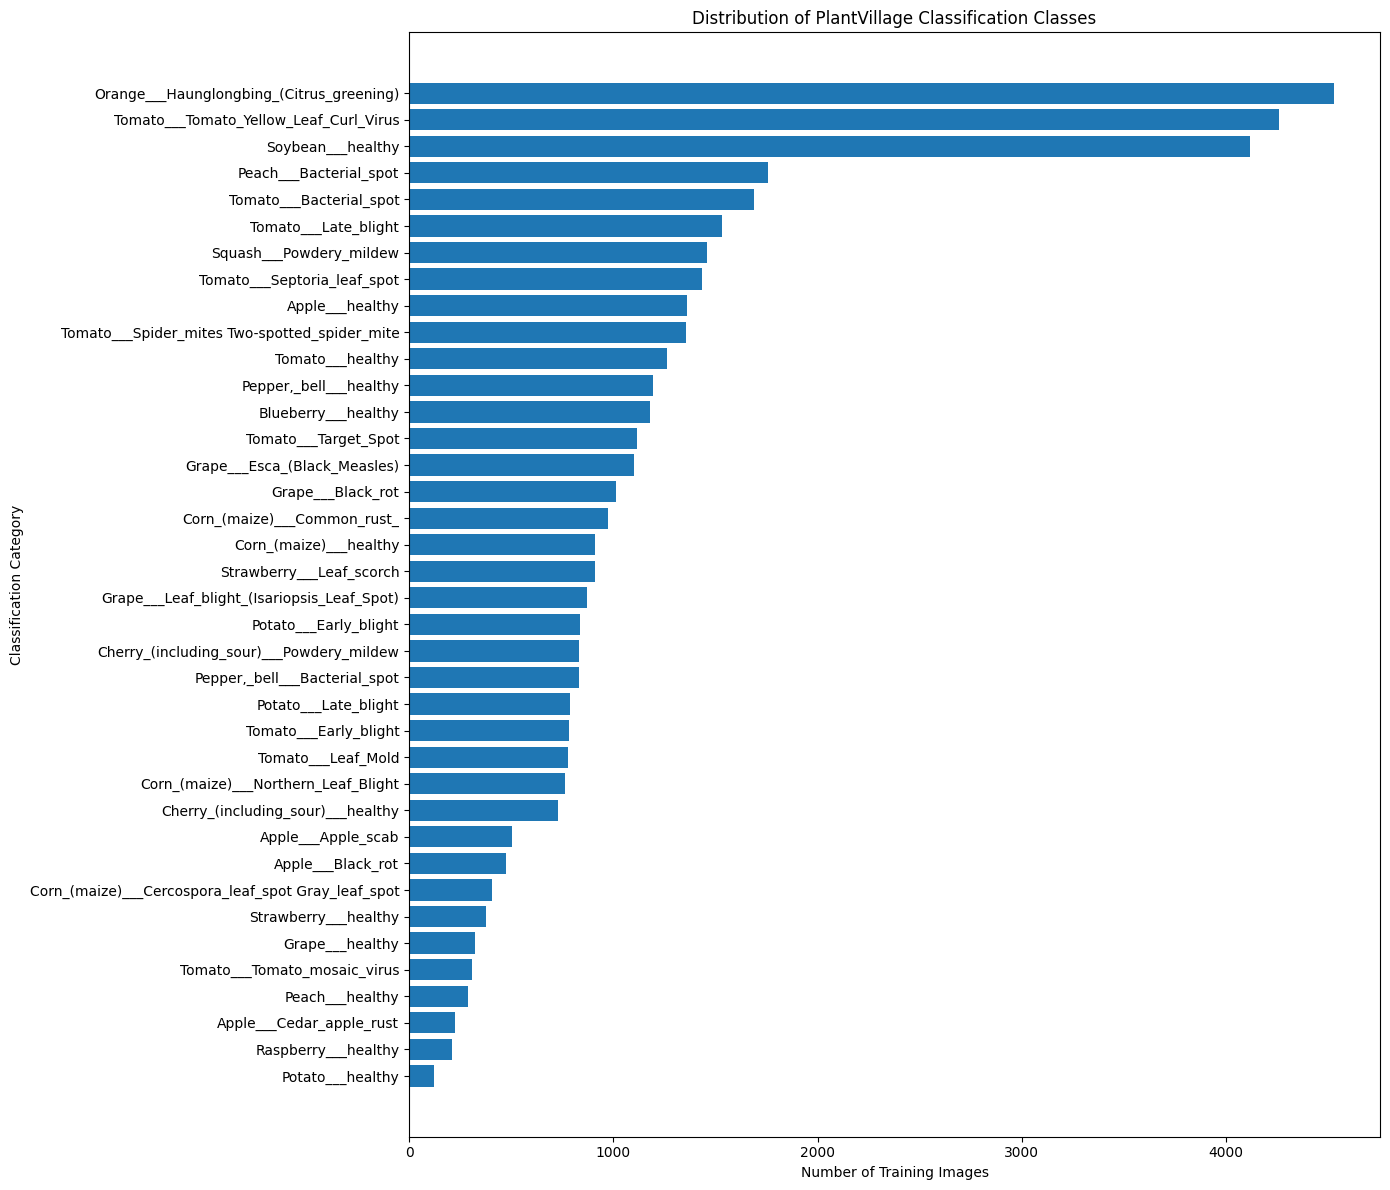

In [5]:
plot_data = class_distribution.sort_values("Number of Images", ascending=True)

plt.figure(figsize=(14, 12))
plt.barh(plot_data["Class Name"], plot_data["Number of Images"])
plt.title("Distribution of PlantVillage Classification Classes")
plt.xlabel("Number of Training Images")
plt.ylabel("Classification Category")
plt.tight_layout()
plt.show()

## 2.1 Visualize sample plant images

We display a random sample of training images with their crop and disease labels. This helps us see the visual task the model must learn, including differences in leaf shape, symptoms, lighting, orientation, and background. The sample is exploratory and cannot represent every image in the dataset. A fixed random seed makes the sample reproducible when dataset ordering is unchanged.

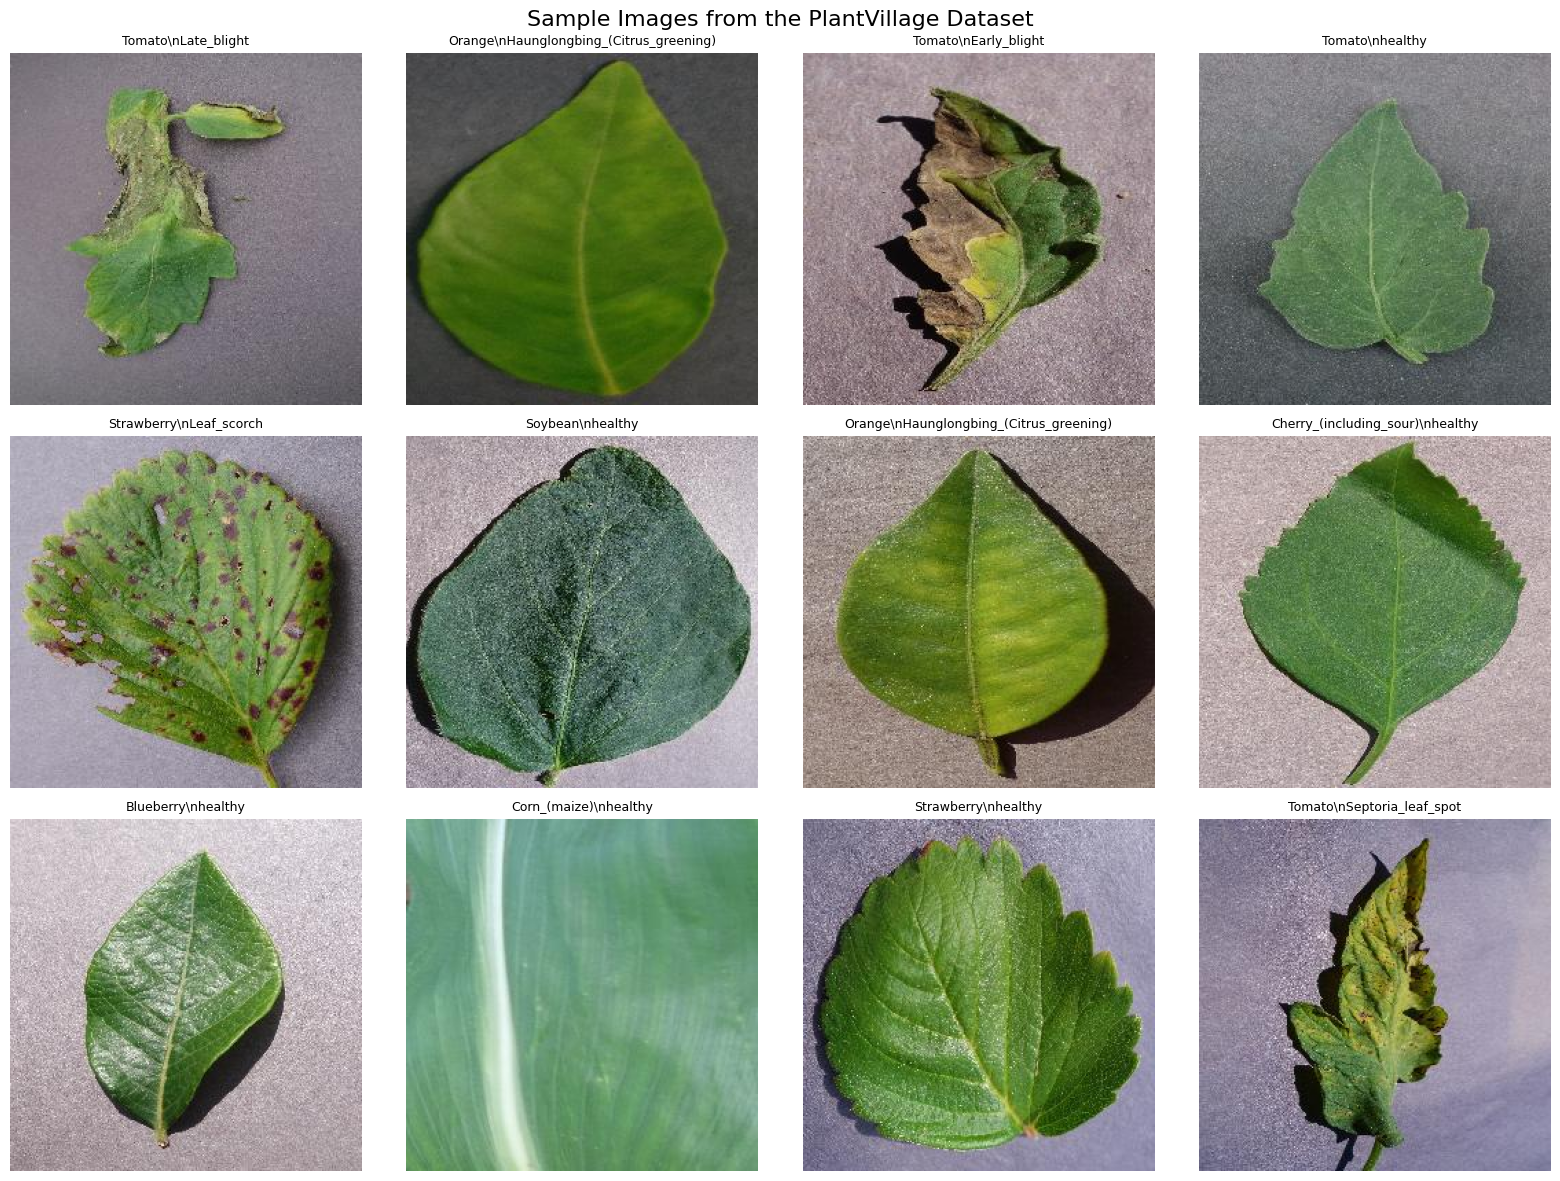

In [6]:
sample_count = min(12, len(train_data))
sample_indices = random.sample(range(len(train_data)), sample_count)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, index in zip(axes.flat, sample_indices):
    sample = train_data[index]
    ax.imshow(sample["image"])
    ax.set_title(f'{sample["crop"]}\\n{sample["disease"]}', fontsize=9)
    ax.axis("off")

for ax in axes.flat[sample_count:]:
    ax.axis("off")

plt.suptitle("Sample Images from the PlantVillage Dataset", fontsize=16)
plt.tight_layout()
plt.show()

### Interpretation – sample images

The sample images show variation in crop types, leaf shapes, and visible symptoms. Healthy leaves generally appear more uniformly coloured, while diseased examples may show spots, yellowing, browning, discoloration, or damaged tissue. These are observations from the displayed examples, not independent diagnoses.

Images also differ in background, lighting, orientation, and framing. The model should learn relevant leaf characteristics rather than relying on irrelevant background cues. We will consider this when designing preprocessing and augmentation. This visualization motivates further checks for image consistency, duplicates, and possible data leakage.

## 2.2 Analyze crop distribution

The `crop` feature identifies the plant type. We count images per crop and visualize the result to determine whether the 14 crops are equally represented. Crop-level imbalance is different from class-level imbalance: a crop may contain several disease classes, while another crop may have only one represented condition. Therefore, this chart must be interpreted alongside the class distribution and crop-disease relationship.

,Crop,Number of Images
0,Tomato,14521
1,Orange,4527
2,Soybean,4117
3,Grape,3306
4,Corn_(maize),3058
5,Apple,2560
6,Peach,2044
7,"Pepper,_bell",2026
8,Potato,1744
9,Cherry_(including_sour),1564


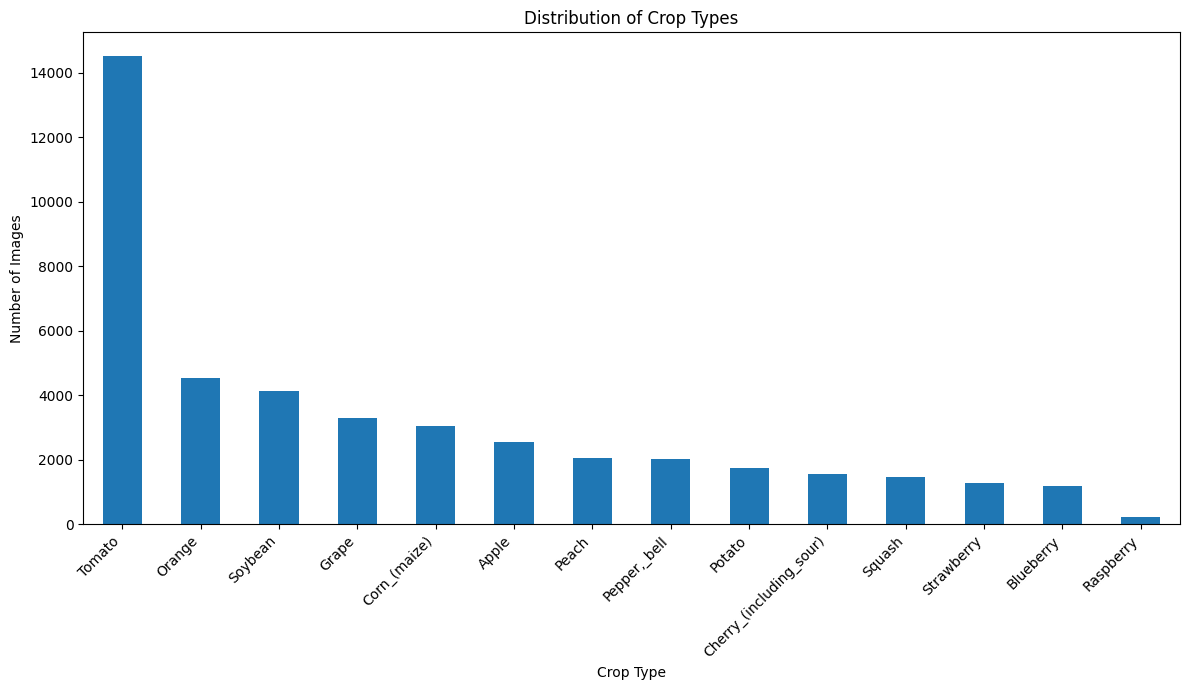

In [7]:
crop_counts = pd.Series(train_data["crop"], name="Crop").value_counts()

display(crop_counts.rename_axis("Crop").reset_index(name="Number of Images"))

plt.figure(figsize=(12, 7))
crop_counts.plot(kind="bar")
plt.title("Distribution of Crop Types")
plt.xlabel("Crop Type")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Interpretation – crop distribution

The training set contains 14 crop types, but their representation is uneven. Tomato is the most represented crop with 14,521 images, while raspberry is the least represented with 209 images. Tomato accounts for approximately 33.31% of the training images and has about 69.5 times as many images as raspberry.

This means the model has substantially more tomato examples available than raspberry examples. However, crop counts alone do not show whether the individual disease classes within each crop are balanced. We will consider both crop-level and crop-disease-level distributions and evaluate model performance across crops.

## 2.3 Analyze healthy versus diseased leaves

We derive a two-group health-status feature from the existing `disease` metadata. Records whose disease value is `healthy` are grouped as healthy; all other records are grouped as diseased. This is a supplementary descriptive analysis, not a replacement for the 38-class prediction task. The combined diseased group contains many different conditions, so its overall count can hide imbalance among individual disease classes.

,Number of Images,Percentage (%)
Health Status,,
Diseased,31526,72.31
Healthy,12070,27.69


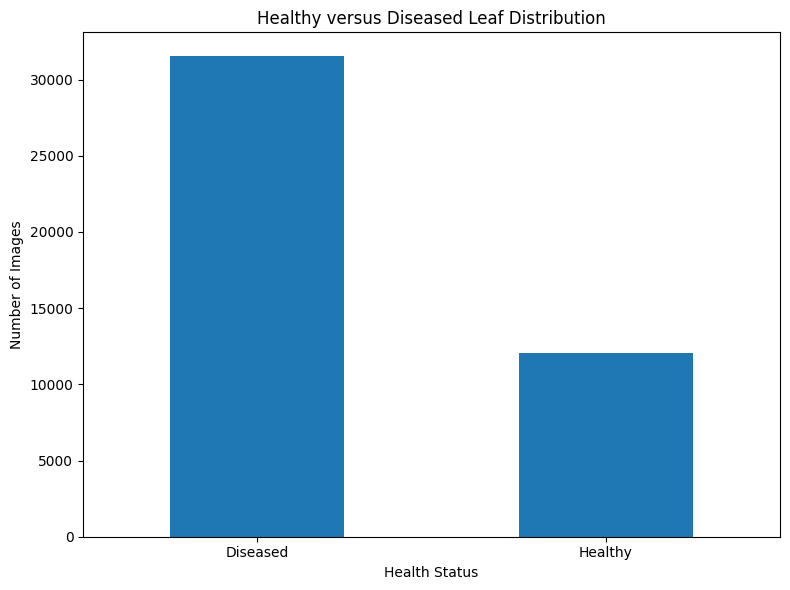

In [8]:
health_data = pd.DataFrame({
    "Crop": train_data["crop"],
    "Disease": train_data["disease"]
})
health_data["Health Status"] = health_data["Disease"].apply(
    lambda value: "Healthy" if str(value).lower() == "healthy" else "Diseased"
)

health_counts = health_data["Health Status"].value_counts()
health_summary = pd.DataFrame({
    "Number of Images": health_counts,
    "Percentage (%)": (health_counts / health_counts.sum() * 100).round(2)
})
display(health_summary)

plt.figure(figsize=(8, 6))
health_counts.plot(kind="bar", rot=0)
plt.title("Healthy versus Diseased Leaf Distribution")
plt.xlabel("Health Status")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

### Interpretation – healthy versus diseased

The training set contains 31,526 diseased images (72.31%) and 12,070 healthy images (27.69%). Diseased images form the larger group overall.

However, this binary grouping combines all disease categories into one group and can hide imbalance among individual classes. For example, there are 120 healthy potato images, compared with 836 potato early-blight images and 788 potato late-blight images. Therefore, the overall healthy/diseased ratio is not enough to describe balance in the 38-class task. We will evaluate individual classes and may report binary health-status performance as supplementary analysis.

## 2.4 Investigate the relationship between crops and diseases

A cross-tabulation counts images for every crop-disease combination. A heatmap makes the pattern easier to inspect. This analysis helps identify which diseases are represented for each crop and explains why a disease name alone can be ambiguous: bacterial spot occurs in peach, bell pepper, and tomato, while early blight occurs in potato and tomato. Dataset coverage should not be confused with the full biological range of diseases that can affect a crop.

Disease,Apple_scab,Bacterial_spot,Black_rot,Cedar_apple_rust,Cercospora_leaf_spot Gray_leaf_spot,Common_rust_,Early_blight,Esca_(Black_Measles),Haunglongbing_(Citrus_greening),Late_blight,...,Leaf_blight_(Isariopsis_Leaf_Spot),Leaf_scorch,Northern_Leaf_Blight,Powdery_mildew,Septoria_leaf_spot,Spider_mites Two-spotted_spider_mite,Target_Spot,Tomato_Yellow_Leaf_Curl_Virus,Tomato_mosaic_virus,healthy
Crop,,,,,,,,,,,,,,,,,,,,,
Apple,503,0,475,223,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1359
Blueberry,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1178
Cherry_(including_sour),0,0,0,0,0,0,0,0,0,0,...,0,0,0,833,0,0,0,0,0,731
Corn_(maize),0,0,0,0,406,975,0,0,0,0,...,0,0,765,0,0,0,0,0,0,912
Grape,0,0,1012,0,0,0,0,1099,0,0,...,872,0,0,0,0,0,0,0,0,323
Orange,0,0,0,0,0,0,0,0,4527,0,...,0,0,0,0,0,0,0,0,0,0
Peach,0,1755,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,289
"Pepper,_bell",0,831,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1195
Potato,0,0,0,0,0,0,836,0,0,788,...,0,0,0,0,0,0,0,0,0,120


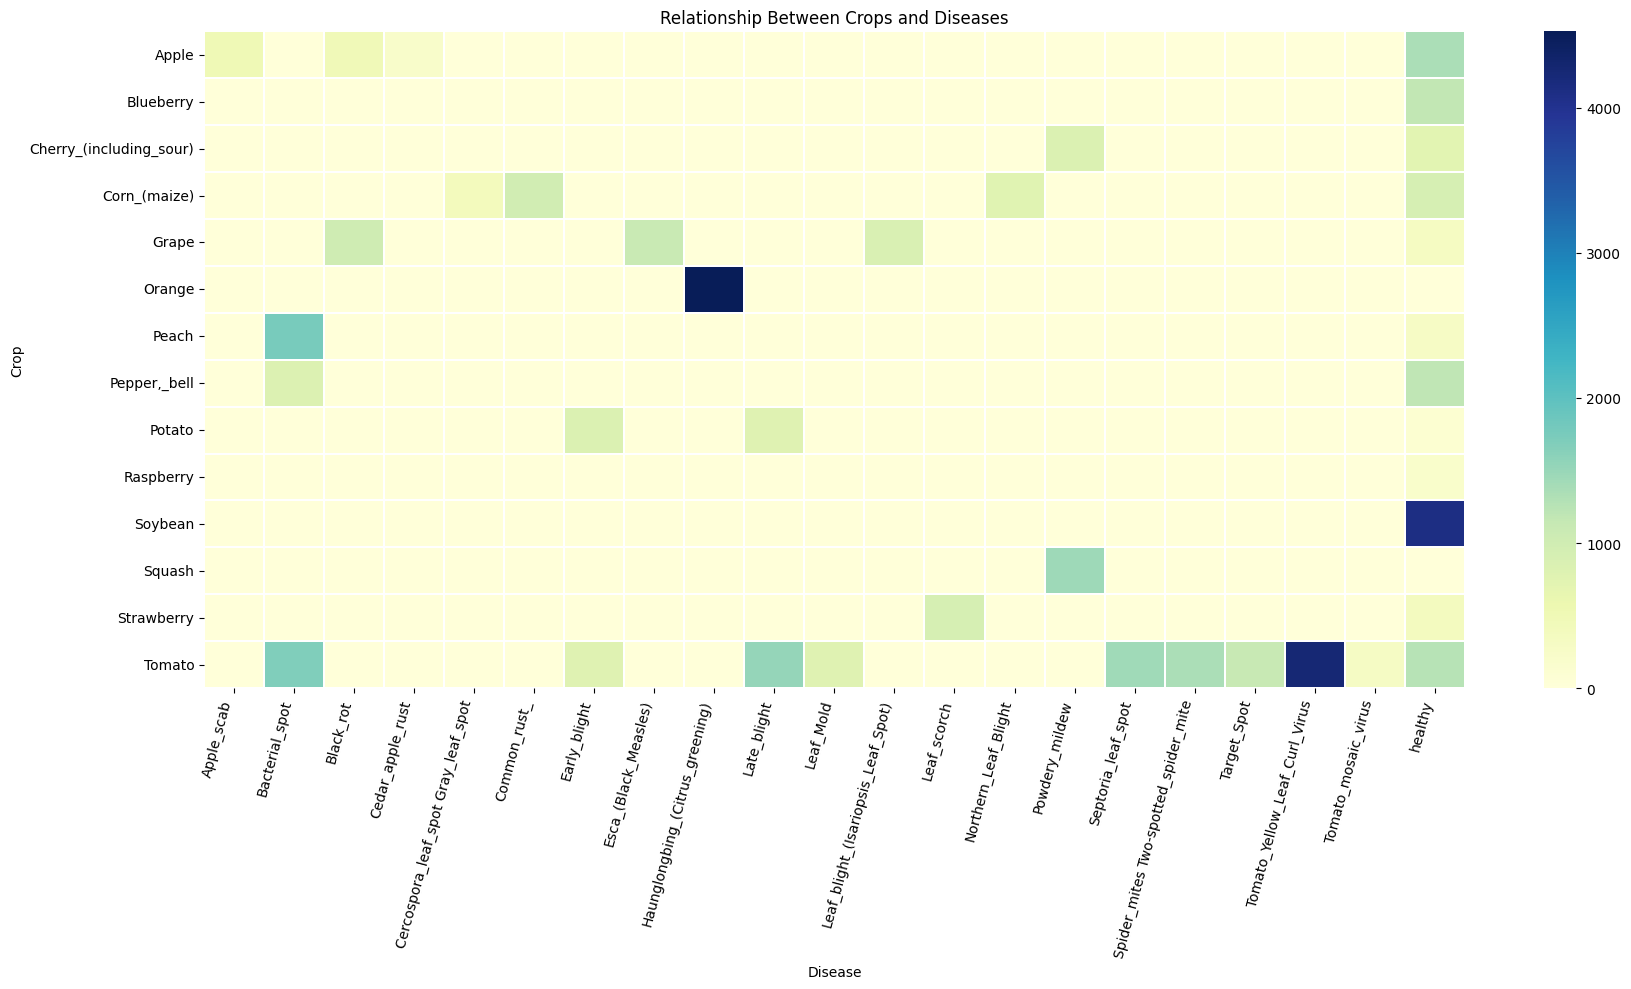

In [9]:
crop_disease_table = pd.crosstab(health_data["Crop"], health_data["Disease"])
display(crop_disease_table)

plt.figure(figsize=(18, 10))
sns.heatmap(crop_disease_table, cmap="YlGnBu", linewidths=0.3, annot=False)
plt.title("Relationship Between Crops and Diseases")
plt.xlabel("Disease")
plt.ylabel("Crop")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

### Interpretation – crop-disease relationship

The crop-disease table shows that crop-disease combinations are not evenly distributed. Tomato has several represented conditions, including bacterial spot, early blight, late blight, leaf mold, Septoria leaf spot, spider mites, target spot, yellow leaf curl virus, tomato mosaic virus, and healthy leaves.

Some disease names occur across crops: bacterial spot appears in peach, bell pepper, and tomato; early blight appears in potato and tomato; powdery mildew appears in cherry and squash. This supports using the combined crop-disease label as the target rather than predicting a disease name without identifying the crop.

Some crops have only one represented condition in this dataset: blueberry, soybean, and raspberry have healthy examples only; orange has citrus greening only; and squash has powdery mildew only. The model cannot learn to distinguish conditions that are absent from the dataset. Its predictions must be interpreted within the dataset's class coverage.

## 2.5 Interpret important dataset features

- **`crop`:** identifies the plant type and supports crop-level distribution analysis.
- **`disease`:** identifies the disease name or `healthy` category and supports health-status and disease analysis.
- **`label`:** encodes the combined crop-disease category and is the supervised learning target.
- **`leaf_id`:** may identify images associated with the same leaf and will be investigated for possible overlap between training and testing.

The image is the model input. The combined label is the target. The other metadata fields support exploration, quality checks, and interpretation; they should not be supplied as hidden shortcuts to an image-only classifier.

# 3. Data Quality Investigation

Before model development, we need to assess whether the dataset is reliable and suitable for training. Corrupted files can cause loading or preprocessing failures. Duplicate images can give repeated examples excessive influence, and duplicates across training and testing can make evaluation overly optimistic. Repeated `leaf_id` values across splits may also indicate related images on both sides of the split.

We will investigate these issues before deciding whether data needs to be excluded or the split needs to be revised. We will not delete or modify original images during this investigation.

## 3.1 Inspect corrupted or unreadable images

We attempt to decode every image in both splits. For readable images, we record image mode, format, and dimensions. For failures, we record the index, path, and error. Different dimensions or modes are not automatically evidence of corruption; they are properties that may inform later preprocessing. This cell is an inspection only and does not remove or alter records.

In [10]:
def inspect_image_readability(dataset_split, split_name):
    corrupted = []
    modes, formats, dimensions = Counter(), Counter(), Counter()

    for index, sample in enumerate(dataset_split):
        try:
            image = sample["image"]
            if image is None:
                raise ValueError("Image field is None")
            image.load()  # Force decoding
            modes[image.mode] += 1
            formats[str(image.format)] += 1
            dimensions[image.size] += 1
        except Exception as error:
            corrupted.append({
                "index": index,
                "image_path": sample.get("image_path"),
                "error": repr(error)
            })

    print(f"\\n{split_name} DATASET INSPECTION")
    print("Total images:", len(dataset_split))
    print("Readable images:", len(dataset_split) - len(corrupted))
    print("Unreadable images:", len(corrupted))
    print("Image modes:", modes)
    print("Image formats:", formats)
    print("Most common dimensions:", dimensions.most_common(10))

    return corrupted, modes, formats, dimensions


train_corrupted, train_modes, train_formats, train_dimensions = (
    inspect_image_readability(train_data, "TRAINING")
)
test_corrupted, test_modes, test_formats, test_dimensions = (
    inspect_image_readability(test_data, "TESTING")
)

if train_corrupted:
    display(pd.DataFrame(train_corrupted).head(20))
if test_corrupted:
    display(pd.DataFrame(test_corrupted).head(20))

\nTRAINING DATASET INSPECTION
Total images: 43596
Readable images: 43596
Unreadable images: 0
Image modes: Counter({'RGB': 43596})
Image formats: Counter({'JPEG': 43596})
Most common dimensions: [((256, 256), 43596)]
\nTESTING DATASET INSPECTION
Total images: 10709
Readable images: 10709
Unreadable images: 0
Image modes: Counter({'RGB': 10708, 'RGBA': 1})
Image formats: Counter({'JPEG': 10708, 'PNG': 1})
Most common dimensions: [((256, 256), 10709)]


## 3.2 Investigate exact duplicate images

We create a content hash for each decoded image after converting it to RGB. The hash uses image dimensions and pixel bytes, so it does not depend on file names or most file metadata. We check duplicates within training, within testing, and across the two splits. An exact duplicate across training and testing is particularly important because test performance may be inflated if the model has already seen identical image content.

This detects exact pixel duplicates after RGB conversion. It does not reliably detect near-duplicates such as resized, compressed, cropped, or slightly altered versions; those require a separate perceptual-hash or embedding-based method.

In [11]:
def image_content_hash(image):
    image = image.convert("RGB")
    content = str(image.size).encode("utf-8") + image.tobytes()
    return hashlib.sha256(content).hexdigest()


def build_hash_index(dataset_split, split_name):
    hash_to_indices = defaultdict(list)
    failures = []

    for index, sample in enumerate(dataset_split):
        try:
            image = sample["image"]
            image.load()
            hash_to_indices[image_content_hash(image)].append(index)
        except Exception as error:
            failures.append((index, repr(error)))

    duplicate_groups = {
        digest: indices for digest, indices in hash_to_indices.items()
        if len(indices) > 1
    }
    excess = sum(len(indices) - 1 for indices in duplicate_groups.values())

    print(f"\n{split_name}")
    print("Unique hashes:", len(hash_to_indices))
    print("Duplicate groups:", len(duplicate_groups))
    print("Duplicate excess images:", excess)
    print("Hashing failures:", len(failures))
    return hash_to_indices, duplicate_groups, failures


train_hash_index, train_duplicate_groups, train_hash_failures = (
    build_hash_index(train_data, "TRAINING DUPLICATE CHECK")
)
test_hash_index, test_duplicate_groups, test_hash_failures = (
    build_hash_index(test_data, "TESTING DUPLICATE CHECK")
)

cross_split_hashes = set(train_hash_index).intersection(test_hash_index)
print("\nExact image hashes found in both splits:", len(cross_split_hashes))

for digest in list(cross_split_hashes)[:10]:
    print(digest[:12], "train:", train_hash_index[digest],
          "test:", test_hash_index[digest])


TRAINING DUPLICATE CHECK
Unique hashes: 43582
Duplicate groups: 14
Duplicate excess images: 14
Hashing failures: 0

TESTING DUPLICATE CHECK
Unique hashes: 10707
Duplicate groups: 2
Duplicate excess images: 2
Hashing failures: 0

Exact image hashes found in both splits: 5
b8c3e6d963cd train: [42479] test: [10150]
c9061b2451ba train: [17751] test: [4118]
7d53bbe0e0fb train: [17162] test: [4095]
1515772fa4a6 train: [42488] test: [10151]
7762db2ea68f train: [41970] test: [10372]


## 3.3 Investigate `leaf_id` and potential data leakage

The `leaf_id` feature may identify images associated with the same physical leaf. We compare identifiers within each split and across training and testing. If the same non-missing ID occurs in both splits, related images may cross the split boundary, making test performance less representative of unseen leaves.

Repeated IDs are a warning to investigate, not automatic proof of leakage. We should confirm what `leaf_id` means from dataset documentation where possible. If IDs identify physical leaves, a group-aware split may be appropriate so that all images from one leaf remain in only one split.

In [12]:
def leaf_id_summary(dataset_split, split_name):
    ids = pd.Series(dataset_split["leaf_id"], dtype="string")
    non_missing = ids.dropna()
    counts = non_missing.value_counts()
    repeated = counts[counts > 1]

    print(f"\n{split_name} LEAF ID SUMMARY")
    print("Total records:", len(ids))
    print("Non-missing IDs:", len(non_missing))
    print("Unique non-missing IDs:", non_missing.nunique())
    print("Missing IDs:", ids.isna().sum())
    print("IDs appearing more than once:", len(repeated))

    if len(repeated):
        display(repeated.head(10).rename_axis("leaf_id").reset_index(
            name="Image Count"
        ))
    return set(non_missing.unique()), counts


train_leaf_ids, train_leaf_counts = leaf_id_summary(train_data, "TRAINING")
test_leaf_ids, test_leaf_counts = leaf_id_summary(test_data, "TESTING")

overlapping_leaf_ids = train_leaf_ids.intersection(test_leaf_ids)
print("\nUnique leaf IDs present in both splits:", len(overlapping_leaf_ids))

if overlapping_leaf_ids:
    overlap_details = [{
        "leaf_id": leaf_id,
        "Training image count": int(train_leaf_counts.get(leaf_id, 0)),
        "Testing image count": int(test_leaf_counts.get(leaf_id, 0))
    } for leaf_id in list(overlapping_leaf_ids)[:20]]
    display(pd.DataFrame(overlap_details))
else:
    print("No shared non-missing leaf IDs were found.")


TRAINING LEAF ID SUMMARY
Total records: 43596
Non-missing IDs: 43596
Unique non-missing IDs: 16124
Missing IDs: 0
IDs appearing more than once: 6529


,leaf_id,Image Count
0,Soybean___healthy:::367.0,33
1,Soybean___healthy:::368.0,28
2,Orange___Haunglongbing_(Citrus_greening):::47.0,25
3,Orange___Haunglongbing_(Citrus_greening):::36.0,24
4,Cherry_(including_sour)___Powdery_mildew:::43.0,24
5,Cherry_(including_sour)___Powdery_mildew:::38.0,23
6,Cherry_(including_sour)___Powdery_mildew:::7.0,23
7,Orange___Haunglongbing_(Citrus_greening):::48.0,23
8,Cherry_(including_sour)___Powdery_mildew:::9.0,23
9,Orange___Haunglongbing_(Citrus_greening):::26.0,23



TESTING LEAF ID SUMMARY
Total records: 10709
Non-missing IDs: 10709
Unique non-missing IDs: 4118
Missing IDs: 0
IDs appearing more than once: 1498


,leaf_id,Image Count
0,Blueberry___healthy:::144.0,29
1,Blueberry___healthy:::152.0,24
2,Cherry_(including_sour)___Powdery_mildew:::11.0,24
3,Cherry_(including_sour)___Powdery_mildew:::35.0,24
4,Cherry_(including_sour)___Powdery_mildew:::23.0,23
5,Raspberry___healthy:::28.0,22
6,Orange___Haunglongbing_(Citrus_greening):::46.0,22
7,Orange___Haunglongbing_(Citrus_greening):::49.0,22
8,Cherry_(including_sour)___Powdery_mildew:::44.0,20
9,Cherry_(including_sour)___Powdery_mildew:::4.0,20



Unique leaf IDs present in both splits: 227


,leaf_id,Training image count,Testing image count
0,fallback_R.S_HL 8207,1,1
1,fallback_R.S_HL 7889,1,1
2,fallback_R.S_HL 8175,1,2
3,fallback_R.S_HL 8235,1,1
4,fallback_R.S_HL 8069,1,1
5,fallback_R.S_HL 8172,1,1
6,fallback_R.S_HL 7894,1,1
7,fallback_R.S_HL 0599,2,2
8,fallback_RS_NLB 0804,2,1
9,fallback_R.S_HL 8048,1,1


### 3.4 Investigating Leaf ID Consistency
In our previous investigation, we discovered that multiple images share the same leaf_id. We also found 227 unique leaf IDs appearing in both the training and testing datasets. However, this alone does not confirm data leakage. We first need to establish whether images sharing an ID belong to the same physical leaf and whether they consistently carry the same classification label.

This cell investigates whether a single leaf ID is associated with multiple disease classifications. We will perform the investigation separately on the training and testing datasets, then examine the combined records. This will help us identify inconsistent labels and understand whether grouping images by leaf_id is appropriate.

In [13]:
def investigate_leaf_consistency(dataset, dataset_name):

    # Extract relevant metadata
    df = pd.DataFrame({
        "leaf_id": dataset["leaf_id"],
        "crop": dataset["crop"],
        "disease": dataset["disease"],
        "label": dataset["label"]
    })

    # Convert numerical class IDs into readable class names
    class_names = dataset.features["label"].names
    df["label_name"] = df["label"].apply(
        lambda x: class_names[x]
    )

    # Group records by leaf ID
    leaf_summary = df.groupby("leaf_id").agg(
        image_count=("label_name", "size"),
        unique_labels=("label_name", "nunique"),
        unique_crops=("crop", "nunique"),
        unique_diseases=("disease", "nunique")
    ).reset_index()

    # Identify leaf IDs associated with multiple labels
    inconsistent = leaf_summary[
        leaf_summary["unique_labels"] > 1
    ]

    print(f"{dataset_name.upper()} LEAF ID CONSISTENCY")

    print("Total unique leaf IDs:", len(leaf_summary))
    print("Leaf IDs with multiple labels:", len(inconsistent))
    print("Percentage of inconsistent IDs:",
          round(len(inconsistent) / len(leaf_summary) * 100, 2), "%")

    print("\nTOP INCONSISTENT LEAF IDs:")

    if len(inconsistent) > 0:
        print(inconsistent.sort_values(
            "unique_labels", ascending=False
        ).head(15).to_string(index=False))
    else:
        print("No inconsistent leaf IDs found.")

    return df, leaf_summary, inconsistent


# Investigate training dataset
train_df, train_leaf_summary, train_inconsistent = (
    investigate_leaf_consistency(
        train_data, "Training"
    )
)

# Investigate testing dataset
test_df, test_leaf_summary, test_inconsistent = (
    investigate_leaf_consistency(
        test_data, "Testing"
    )
)


TRAINING LEAF ID CONSISTENCY
Total unique leaf IDs: 16124
Leaf IDs with multiple labels: 0
Percentage of inconsistent IDs: 0.0 %

TOP INCONSISTENT LEAF IDs:
No inconsistent leaf IDs found.
TESTING LEAF ID CONSISTENCY
Total unique leaf IDs: 4118
Leaf IDs with multiple labels: 0
Percentage of inconsistent IDs: 0.0 %

TOP INCONSISTENT LEAF IDs:
No inconsistent leaf IDs found.


In [14]:
# Find leaf IDs appearing in both datasets
shared_leaf_ids = set(train_df["leaf_id"]) & set(test_df["leaf_id"])

# Filter records belonging to shared IDs
train_shared = train_df[
    train_df["leaf_id"].isin(shared_leaf_ids)
].copy()

test_shared = test_df[
    test_df["leaf_id"].isin(shared_leaf_ids)
].copy()

# Compare labels across the two datasets
train_labels = train_shared.groupby("leaf_id")["label_name"].agg(set)
test_labels = test_shared.groupby("leaf_id")["label_name"].agg(set)

comparison = pd.DataFrame({
    "training_labels": train_labels,
    "testing_labels": test_labels
})

comparison["same_labels"] = comparison.apply(
    lambda row: row["training_labels"] == row["testing_labels"],
    axis=1
)

comparison["label_overlap"] = comparison.apply(
    lambda row: bool(
        row["training_labels"] & row["testing_labels"]
    ),
    axis=1
)

print("\nCROSS-SPLIT LEAF ID INVESTIGATION")

print("Shared leaf IDs:", len(shared_leaf_ids))

print(
    "IDs with identical label sets:",
    comparison["same_labels"].sum()
)

print(
    "IDs with at least one matching label:",
    comparison["label_overlap"].sum()
)

print(
    "IDs with no matching labels:",
    (~comparison["label_overlap"]).sum()
)

print("\nEXAMPLES OF SHARED LEAF IDs:")
print(comparison.head(15).to_string())



CROSS-SPLIT LEAF ID INVESTIGATION
Shared leaf IDs: 227
IDs with identical label sets: 227
IDs with at least one matching label: 227
IDs with no matching labels: 0

EXAMPLES OF SHARED LEAF IDs:
                                             training_labels             testing_labels  same_labels  label_overlap
leaf_id                                                                                                            
fallback_GHLB2 Leaf 8999              {Tomato___Late_blight}     {Tomato___Late_blight}         True           True
fallback_GHLB_PS Leaf 23.7 Day 13     {Tomato___Late_blight}     {Tomato___Late_blight}         True           True
fallback_GHLB_PS Leaf 24 Day 16       {Tomato___Late_blight}     {Tomato___Late_blight}         True           True
fallback_GH_HL Leaf 220                   {Tomato___healthy}         {Tomato___healthy}         True           True
fallback_GH_HL Leaf 466.1                 {Tomato___healthy}         {Tomato___healthy}         True          

### 3.5 Investigating Shared Leaf IDs Across Training and Testing

In this section, we investigate the 227 leaf IDs that appear in both the training and testing datasets.

Although all shared IDs have consistent classification labels, their presence across both splits may introduce data leakage if multiple images associated with the same physical leaf or image group are distributed between training and testing.

We will examine the number of images associated with each shared ID in both datasets, identify the IDs contributing the most images, and calculate the proportion of the datasets affected.

This investigation will help us determine whether the current train/test split provides a sufficiently independent evaluation of model performance.

We will preserve the original datasets and use the findings to guide our preprocessing and data-splitting strategy.

In [15]:

# Investigate the distribution of shared leaf IDs

# Count images associated with each shared leaf ID
train_shared_counts = (
    train_df[train_df["leaf_id"].isin(shared_leaf_ids)]
    .groupby("leaf_id")
    .size()
    .rename("training_images")
)

test_shared_counts = (
    test_df[test_df["leaf_id"].isin(shared_leaf_ids)]
    .groupby("leaf_id")
    .size()
    .rename("testing_images")
)

# Combine the counts
shared_leaf_summary = pd.concat(
    [train_shared_counts, test_shared_counts],
    axis=1
).fillna(0)

shared_leaf_summary["total_images"] = (
    shared_leaf_summary["training_images"]
    + shared_leaf_summary["testing_images"]
)

# Sort by the total number of images
shared_leaf_summary = shared_leaf_summary.sort_values(
    "total_images", ascending=False
)

print("SHARED LEAF ID STATISTICS")

print("Number of shared leaf IDs:", len(shared_leaf_summary))

print(
    "Training images involved:",
    int(shared_leaf_summary["training_images"].sum())
)

print(
    "Testing images involved:",
    int(shared_leaf_summary["testing_images"].sum())
)

print(
    "Total images involved:",
    int(shared_leaf_summary["total_images"].sum())
)

print(
    "Percentage of training dataset affected:",
    round(
        shared_leaf_summary["training_images"].sum()
        / len(train_df) * 100, 2
    ), "%"
)

print(
    "Percentage of testing dataset affected:",
    round(
        shared_leaf_summary["testing_images"].sum()
        / len(test_df) * 100, 2
    ), "%"
)

print("\nTOP 15 SHARED LEAF IDs")
display(shared_leaf_summary.head(15))


SHARED LEAF ID STATISTICS
Number of shared leaf IDs: 227
Training images involved: 290
Testing images involved: 243
Total images involved: 533
Percentage of training dataset affected: 0.67 %
Percentage of testing dataset affected: 2.27 %

TOP 15 SHARED LEAF IDs


,training_images,testing_images,total_images
leaf_id,,,
fallback_R.S_HL 0646,4,1,5
fallback_R.S_HL 0598,3,1,4
fallback_R.S_HL 0600,2,2,4
fallback_R.S_HL 0623,2,2,4
fallback_R.S_HL 0651,1,3,4
fallback_R.S_HL 0599,2,2,4
fallback_R.S_HL 8220,3,1,4
fallback_R.S_HL 8330,3,1,4
fallback_R.S_HL 0635,1,2,3


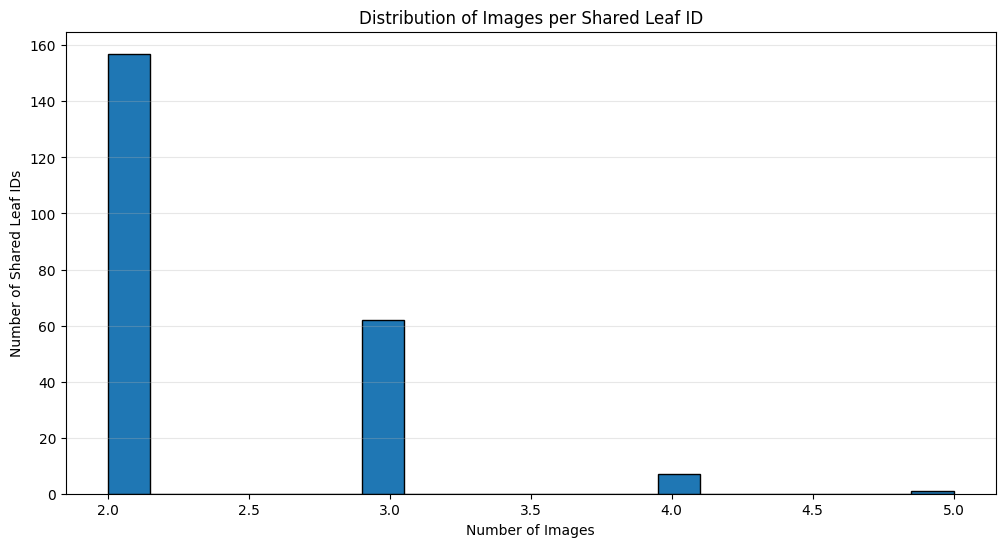

In [16]:

# Visualize the number of images per shared leaf ID

plt.figure(figsize=(12, 6))

shared_leaf_summary["total_images"].plot(
    kind="hist",
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Images per Shared Leaf ID")
plt.xlabel("Number of Images")
plt.ylabel("Number of Shared Leaf IDs")
plt.grid(axis="y", alpha=0.3)

plt.show()


### 3.6 Preparing the Cleaned Evaluation Dataset

Based on the data-quality investigation, we identified 227 leaf IDs appearing in both the training and testing datasets. We also identified five exact duplicate images shared across the two splits.

To reduce potential data leakage and obtain a more reliable evaluation, we will exclude the affected testing images from our evaluation dataset.

The original training and testing datasets will remain unchanged. Instead, we will create a separate cleaned testing dataset.

We will retain all training images because the objective is to maximize the available training data while ensuring that the evaluation images do not share identified leaf IDs or exact duplicate images with the training set.

This cleaning decision is based on the available metadata and exact image hashes. The reliability of the leaf IDs as physical-leaf identifiers remains an assumption that should be documented.

In [17]:

# Identify testing images whose leaf IDs also appear in training
shared_leaf_test_indices = set(
    test_df.index[
        test_df["leaf_id"].isin(shared_leaf_ids)
    ].tolist()
)

# Exact duplicate image indexes previously identified in the testing dataset
cross_split_duplicate_test_indices = {
    4118,
    4095,
    10150,
    10151,
    10372
}

# Combine both exclusion groups
excluded_test_indices = (
    shared_leaf_test_indices
    | cross_split_duplicate_test_indices
)

# Preserve the original test_data
# Create a new testing dataset containing only retained images
test_keep_indices = [
    i for i in range(len(test_data))
    if i not in excluded_test_indices
]

test_data_clean = test_data.select(test_keep_indices)

print("FINAL DATASET SIZES")

print("Original training images:", len(train_data))
print("Cleaned training images:", len(train_data))

print("Original testing images:", len(test_data))
print("Cleaned testing images:", len(test_data_clean))

print("\nCLEANING SUMMARY")

print("Testing images excluded:", len(excluded_test_indices))
print("Testing images retained:", len(test_data_clean))

print(
    "Percentage of testing images excluded:",
    round(
        len(excluded_test_indices) / len(test_data) * 100,
        2
    ),
    "%"
)


FINAL DATASET SIZES
Original training images: 43596
Cleaned training images: 43596
Original testing images: 10709
Cleaned testing images: 10466

CLEANING SUMMARY
Testing images excluded: 243
Testing images retained: 10466
Percentage of testing images excluded: 2.27 %


In [18]:

# Confirm that no identified leaf IDs remain in both splits

remaining_shared_leaf_ids = (
    set(train_data["leaf_id"])
    & set(test_data_clean["leaf_id"])
)

print("FINAL LEAF ID OVERLAP CHECK")

print("Remaining shared leaf IDs:", len(remaining_shared_leaf_ids))

if len(remaining_shared_leaf_ids) == 0:
    print("SUCCESS: No shared leaf IDs remain.")
else:
    print("WARNING: Shared leaf IDs still exist.")


FINAL LEAF ID OVERLAP CHECK
Remaining shared leaf IDs: 0
SUCCESS: No shared leaf IDs remain.


### 3.7 Removing Exact Duplicate Images

In this step, we will remove exact duplicate images from the training and testing datasets.

We will use image hashing to identify identical images, retain only one copy of each duplicate, and record the removed images for documentation.

The original datasets will remain unchanged. This will help prevent repeated images from unnecessarily influencing model training and evaluation.

In [19]:
def remove_exact_duplicates(dataset, dataset_name, original_indices=None):
    """
    Remove exact duplicate images while preserving the first occurrence.

    Returns:
        cleaned_dataset: Dataset without exact duplicates.
        duplicate_records: DataFrame documenting removed images.
    """

    seen_hashes = {}
    keep_indices = []
    duplicate_records = []

    class_names = dataset.features["label"].names

    for i in range(len(dataset)):
        image = dataset[i]["image"]

        # Standardize representation before hashing
        image = image.convert("RGB")

        # Include image dimensions in the hash
        image_hash = hashlib.sha256(
            str(image.size).encode() + image.tobytes()
        ).hexdigest()

        original_index = (
            original_indices[i]
            if original_indices is not None
            else i
        )

        if image_hash not in seen_hashes:
            seen_hashes[image_hash] = original_index
            keep_indices.append(i)

        else:
            duplicate_records.append({
                "dataset": dataset_name,
                "original_index": original_index,
                "kept_original_index": seen_hashes[image_hash],
                "leaf_id": dataset[i]["leaf_id"],
                "label": class_names[dataset[i]["label"]],
                "image_hash": image_hash
            })

    cleaned_dataset = dataset.select(keep_indices)

    duplicate_df = pd.DataFrame(duplicate_records)

    print(f"\n{dataset_name.upper()} DUPLICATE REMOVAL")
    print("Original images:", len(dataset))
    print("Images retained:", len(cleaned_dataset))
    print("Duplicate images removed:", len(duplicate_df))

    return cleaned_dataset, duplicate_df


# Remove duplicates from training
train_data_dedup, train_duplicates = remove_exact_duplicates(
    train_data,
    "Training"
)

# Remove duplicates from the cleaned testing dataset.
# Preserve indexes from the original testing dataset in the records.
test_data_dedup, test_duplicates = remove_exact_duplicates(
    test_data_clean,
    "Testing",
    original_indices=test_keep_indices
)

# Combine duplicate removal records
all_duplicate_records = pd.concat(
    [train_duplicates, test_duplicates],
    ignore_index=True
)

print("\nOVERALL DUPLICATE REMOVAL SUMMARY")
print("Total duplicates removed:", len(all_duplicate_records))
print("Final training images:", len(train_data_dedup))
print("Final testing images:", len(test_data_dedup))

display(all_duplicate_records.head(20))



TRAINING DUPLICATE REMOVAL
Original images: 43596
Images retained: 43582
Duplicate images removed: 14

TESTING DUPLICATE REMOVAL
Original images: 10466
Images retained: 10464
Duplicate images removed: 2

OVERALL DUPLICATE REMOVAL SUMMARY
Total duplicates removed: 16
Final training images: 43582
Final testing images: 10464


,dataset,original_index,kept_original_index,leaf_id,label,image_hash
0,Training,3264,3263,Apple___healthy:::105.0,Apple___healthy,17dc46a6c4e4114ad7c5f726a9c5dc50cbf226f19a1fcb...
1,Training,3268,3261,Apple___healthy:::105.0,Apple___healthy,3cb2975e33d2a136f1b7a00953d9731994910ecdc9f1ef...
2,Training,3269,3267,Apple___healthy:::105.0,Apple___healthy,24e9f739ff6ba37925b2d455b9cad0abf5fd2b58ce0659...
3,Training,3270,3266,Apple___healthy:::105.0,Apple___healthy,9108ef7022d8c951fb3738adeebe18a97be11be4dabf1b...
4,Training,3271,3262,Apple___healthy:::105.0,Apple___healthy,b263cc559a6f886f43681c5b2c8630809864420457e722...
5,Training,17390,16997,fallback_GH_HL Leaf 482.2,Tomato___healthy,0eaf0d56ff8151cb46533813ef89d9f9bd76817167936d...
6,Training,17514,17298,fallback_GH_HL Leaf 342.1,Tomato___healthy,935402dee374cf95271d0676688c8600b48422cb552182...
7,Training,17749,17263,fallback_GH_HL Leaf 389,Tomato___healthy,9350d6480a94ea3f7b11e43684351f19ee7231a68c321e...
8,Training,18033,17116,fallback_GH_HL Leaf 434,Tomato___healthy,64adebdc5d87128d79579273fc3808d095eb32d9bc058d...
9,Training,42056,41913,fallback_GHLB_PS Leaf 24 Day 13,Tomato___Late_blight,0668be035d967718fab9bdb1b4bae3ec4263cb9d40e421...


In [28]:

all_duplicate_records.to_csv(
    "../data/duplicate_removal_records.csv",
    index=False
)

print("Duplicate removal records saved successfully.")
print("File: duplicate_removal_records.csv")


Duplicate removal records saved successfully.
File: duplicate_removal_records.csv


### 3.8 Creating Leakage-Free Dataset Splits

In this step, we will organize our data into training, validation, and testing datasets.

We will use group-based splitting with the `leaf_id` feature to ensure that images belonging to the same identified leaf group do not appear across different splits.

We will preserve the cleaned testing dataset and create a validation dataset from the training data. This will help us evaluate model performance more reliably and reduce potential data leakage.

In [21]:
# Extract labels and leaf IDs from the deduplicated training dataset
train_labels = np.array(train_data_dedup["label"])
train_groups = np.array(train_data_dedup["leaf_id"])

# Create a stratified group splitter
group_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate approximately 80% training and 20% validation
train_indices, val_indices = next(
    group_splitter.split(
        X=np.zeros(len(train_data_dedup)),
        y=train_labels,
        groups=train_groups
    )
)

# Create the final training and validation datasets
train_data_final = train_data_dedup.select(
    train_indices.tolist()
)

val_data = train_data_dedup.select(
    val_indices.tolist()
)

# Keep our cleaned testing dataset unchanged
test_data_final = test_data_dedup

print("DATASET SPLITTING RESULTS")

print("Training images:", len(train_data_final))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data_final))

print("\nDATASET PROPORTIONS")

total_images = (
    len(train_data_final)
    + len(val_data)
    + len(test_data_final)
)

print(
    "Training:",
    round(len(train_data_final) / total_images * 100, 2),
    "%"
)

print(
    "Validation:",
    round(len(val_data) / total_images * 100, 2),
    "%"
)

print(
    "Testing:",
    round(len(test_data_final) / total_images * 100, 2),
    "%"
)


DATASET SPLITTING RESULTS
Training images: 34880
Validation images: 8702
Testing images: 10464

DATASET PROPORTIONS
Training: 64.54 %
Validation: 16.1 %
Testing: 19.36 %


### 3.9 Standardizing Image Formats

In this step, we will standardize the image representation across all datasets.

We will convert images to RGB format, ensure consistent image dimensions, and prepare them for the model's input requirements.

This will ensure that the model receives images in a consistent format during training, validation, and prediction.

In [22]:

def inspect_image_formats(dataset, dataset_name):
    modes = {}
    dimensions = {}

    for example in dataset:
        image = example["image"]

        modes[image.mode] = modes.get(image.mode, 0) + 1
        dimensions[image.size] = dimensions.get(image.size, 0) + 1

    print(f"\n{dataset_name.upper()} IMAGE INSPECTION")
    print("Image modes:", modes)
    print("Image dimensions:", dimensions)


inspect_image_formats(train_data_final, "Training")
inspect_image_formats(val_data, "Validation")
inspect_image_formats(test_data_final, "Testing")



TRAINING IMAGE INSPECTION
Image modes: {'RGB': 34880}
Image dimensions: {(256, 256): 34880}

VALIDATION IMAGE INSPECTION
Image modes: {'RGB': 8702}
Image dimensions: {(256, 256): 8702}

TESTING IMAGE INSPECTION
Image modes: {'RGB': 10463, 'RGBA': 1}
Image dimensions: {(256, 256): 10464}


RGBA image indexes: [5560]
Original mode: RGBA
Original dimensions: (256, 256)
Number of channels: 4


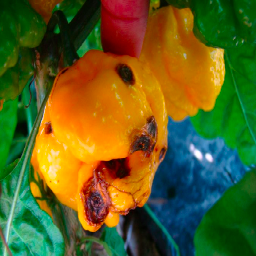

In [23]:

# Find the RGBA image in the testing dataset

rgba_indices = [
    i for i, example in enumerate(test_data_final)
    if example["image"].mode == "RGBA"
]

print("RGBA image indexes:", rgba_indices)

if rgba_indices:
    rgba_image = test_data_final[rgba_indices[0]]["image"]

    print("Original mode:", rgba_image.mode)
    print("Original dimensions:", rgba_image.size)
    print("Number of channels:", len(rgba_image.getbands()))

    display(rgba_image)


In [24]:
# Convert only images that are not already RGB

def convert_to_rgb_if_needed(example):
    image = example["image"]

    if image.mode != "RGB":
        image = image.convert("RGB")

    return {"image": image}


# Training and validation are already RGB, so reuse them.
train_data_ready = train_data_final
val_data_ready = val_data

# Convert the exceptional image in testing
test_data_ready = test_data_final.map(
    convert_to_rgb_if_needed,
    desc="Converting non-RGB testing images"
)

print("IMAGE STANDARDIZATION COMPLETED")
print("Training images:", len(train_data_ready))
print("Validation images:", len(val_data_ready))
print("Testing images:", len(test_data_ready))


IMAGE STANDARDIZATION COMPLETED
Training images: 34880
Validation images: 8702
Testing images: 10464


In [25]:
inspect_image_formats(train_data_ready, "Training")
inspect_image_formats(val_data_ready, "Validation")
inspect_image_formats(test_data_ready, "Testing")


TRAINING IMAGE INSPECTION
Image modes: {'RGB': 34880}
Image dimensions: {(256, 256): 34880}

VALIDATION IMAGE INSPECTION
Image modes: {'RGB': 8702}
Image dimensions: {(256, 256): 8702}

TESTING IMAGE INSPECTION
Image modes: {'RGB': 10464}
Image dimensions: {(256, 256): 10464}


### 3.10 Validating the Cleaned Dataset

In this final data preparation step, we will verify the quality and consistency of our cleaned datasets.

We will check image counts, class distributions, duplicate images, image formats, and leaf ID overlap across the training, validation, and testing datasets.

We will also confirm that all images are readable and ready for model training.

This validation will help ensure that our datasets are reliable before proceeding to model development.

In [26]:
# The final datasets to validate
datasets = {
    "Training": train_data_ready,
    "Validation": val_data_ready,
    "Testing": test_data_ready
}

# 1. Dataset sizes
print("DATASET SIZES")
for name, dataset in datasets.items():
    print(f"{name}: {len(dataset):,} images")


# 2. Class distributions
class_names = train_data_final.features["label"].names

distribution_records = []

for name, dataset in datasets.items():
    counts = Counter(dataset["label"])

    for label_id, class_name in enumerate(class_names):
        distribution_records.append({
            "Dataset": name,
            "Class": class_name,
            "Image Count": counts.get(label_id, 0),
            "Percentage": round(
                counts.get(label_id, 0) / len(dataset) * 100, 2
            )
        })

class_distribution_df = pd.DataFrame(distribution_records)

print("CLASS DISTRIBUTION")
display(
    class_distribution_df.pivot(
        index="Class",
        columns="Dataset",
        values="Image Count"
    ).fillna(0).astype(int)
)


# 3. Leaf ID overlap
train_leaf_ids = set(train_data_ready["leaf_id"])
val_leaf_ids = set(val_data_ready["leaf_id"])
test_leaf_ids = set(test_data_ready["leaf_id"])

overlap_results = {
    "Training-Validation": train_leaf_ids & val_leaf_ids,
    "Training-Testing": train_leaf_ids & test_leaf_ids,
    "Validation-Testing": val_leaf_ids & test_leaf_ids
}

print("LEAF ID OVERLAP")
for comparison, overlapping_ids in overlap_results.items():
    print(f"{comparison}: {len(overlapping_ids)} overlapping IDs")


# 4. Exact duplicate image verification across all splits
def calculate_image_hashes(dataset):
    hashes = []

    for example in dataset:
        image = example["image"].convert("RGB")
        image_hash = hashlib.sha256(
            str(image.size).encode() + image.tobytes()
        ).hexdigest()
        hashes.append(image_hash)

    return set(hashes), len(hashes)

dataset_hashes = {}

for name, dataset in datasets.items():
    dataset_hashes[name], _ = calculate_image_hashes(dataset)

print("EXACT DUPLICATE CHECK")
for first, second in [
    ("Training", "Validation"),
    ("Training", "Testing"),
    ("Validation", "Testing")
]:
    duplicates = dataset_hashes[first] & dataset_hashes[second]
    print(f"{first}-{second}: {len(duplicates)} shared image hashes")

# 5. Final image format and dimension verification
print("\nIMAGE FORMAT AND DIMENSION CHECK")

for name, dataset in datasets.items():
    modes = Counter()
    dimensions = Counter()
    unreadable = []

    for index, example in enumerate(dataset):
        try:
            image = example["image"]
            image.load()
            modes[image.mode] += 1
            dimensions[image.size] += 1
        except Exception as error:
            unreadable.append((index, str(error)))

    print(f"\n{name}")
    print("Image modes:", dict(modes))
    print("Image dimensions:", dict(dimensions))
    print("Unreadable images:", len(unreadable))

print("\nFINAL VALIDATION COMPLETED")

DATASET SIZES
Training: 34,880 images
Validation: 8,702 images
Testing: 10,464 images
CLASS DISTRIBUTION


Dataset,Testing,Training,Validation
Class,,,
Apple___Apple_scab,127,419,84
Apple___Black_rot,146,392,83
Apple___Cedar_apple_rust,52,180,43
Apple___healthy,284,1073,281
Blueberry___healthy,324,929,249
Cherry_(including_sour)___Powdery_mildew,219,689,144
Cherry_(including_sour)___healthy,123,585,146
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,88,312,94
Corn_(maize)___Common_rust_,217,780,195


LEAF ID OVERLAP
Training-Validation: 0 overlapping IDs
Training-Testing: 0 overlapping IDs
Validation-Testing: 0 overlapping IDs
EXACT DUPLICATE CHECK
Training-Validation: 0 shared image hashes
Training-Testing: 0 shared image hashes
Validation-Testing: 0 shared image hashes

IMAGE FORMAT AND DIMENSION CHECK

Training
Image modes: {'RGB': 34880}
Image dimensions: {(256, 256): 34880}
Unreadable images: 0

Validation
Image modes: {'RGB': 8702}
Image dimensions: {(256, 256): 8702}
Unreadable images: 0

Testing
Image modes: {'RGB': 10464}
Image dimensions: {(256, 256): 10464}
Unreadable images: 0

FINAL VALIDATION COMPLETED


### 3.11 Saving the Prepared Datasets
In this step, we will save the cleaned and standardized training, validation, and testing datasets. These datasets will be transferred to Google Colab for model development, allowing us to reuse the prepared data without repeating the preprocessing and splitting stages.


In [29]:
# Create a DatasetDict containing our final datasets
prepared_datasets = DatasetDict({
    "train": train_data_ready,
    "validation": val_data_ready,
    "test": test_data_ready
})

# 2. Define the output directory
output_dir = Path("../data/cleaned_data/plantvillage_prepared")
output_dir.parent.mkdir(parents=True, exist_ok=True)

# Avoid accidentally overwriting an existing dataset
if output_dir.exists():
    raise FileExistsError(
        f"{output_dir} already exists. Choose another output directory "
        "or rename the existing folder before saving."
    )

# 3. Save datasets in Hugging Face format
prepared_datasets.save_to_disk(str(output_dir))

# 4. Save dataset information and class mapping
class_names = train_data_ready.features["label"].names

metadata = {
    "project": "PlantVillage Plant Disease Classification",
    "number_of_classes": len(class_names),
    "class_names": class_names,
    "image_dimensions": [256, 256],
    "image_mode": "RGB",
    "dataset_sizes": {
        "train": len(train_data_ready),
        "validation": len(val_data_ready),
        "test": len(test_data_ready)
    }
}

with open(output_dir / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

# 5. Package the saved datasets into a ZIP file
zip_path = output_dir.parent / "plantvillage_prepared.zip"

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_STORED
) as zip_file:
    for file_path in output_dir.rglob("*"):
        if file_path.is_file():
            archive_name = (
                Path(output_dir.name) / file_path.relative_to(output_dir)
            )
            zip_file.write(file_path, archive_name)

# 6. Display saving results
print("DATASET EXPORT COMPLETED")

for split, dataset in prepared_datasets.items():
    print(f"{split.capitalize()}: {len(dataset):,} images")

print(f"\nNumber of classes: {len(class_names)}")
print(f"Dataset directory: {output_dir}")
print(f"ZIP archive: {zip_path}")
print(f"ZIP size: {zip_path.stat().st_size / (1024**2):.2f} MB")


Saving the dataset (0/2 shards):   0%|          | 0/34880 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/8702 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/10464 [00:00<?, ? examples/s]

DATASET EXPORT COMPLETED
Train: 34,880 images
Validation: 8,702 images
Test: 10,464 images

Number of classes: 38
Dataset directory: ../data/cleaned_data/plantvillage_prepared
ZIP archive: ../data/cleaned_data/plantvillage_prepared.zip
ZIP size: 820.49 MB


### 3.11 Conclusion: Data Understanding and Preparation

In this notebook, we successfully completed the data understanding, exploration, cleaning, and preparation stages of our PlantVillage image classification project.

We explored the dataset, investigated crop and disease distributions, examined image quality, identified duplicate images, and investigated leaf IDs to reduce potential data leakage.

We retained all **14 crops and 38 classification classes** to develop a unified plant disease classification model.

#### Final Dataset Summary

After cleaning and splitting, the datasets contain:

| Dataset | Number of Images |
|---|---:|
| Training | 34,880 |
| Validation | 8,702 |
| Testing | 10,464 |
| **Total** | **54,046** |

#### Data Quality and Validation Results

The final validation confirmed that:

- All 38 classes are represented in the training, validation, and testing datasets.
- All images are readable.
- All images have been standardized to RGB format.
- All images have consistent dimensions of 256 × 256 pixels.
- No leaf IDs overlap between the training, validation, and testing datasets.
- No exact duplicate images exist across the three datasets.

We also identified class imbalance in the dataset. Rather than removing classes with fewer images, we retained all classes to preserve the project's classification scope. We will consider appropriate techniques during model development to address this imbalance.

#### Transition to Model Development

With data preparation complete, we will proceed to the model development stage in a separate notebook titled:

**02_model_training.ipynb**

In the next notebook, we will:

1. Load the prepared training, validation, and testing datasets.
2. Define the image preprocessing required by the selected model architecture.
3. Build a baseline image classification model using transfer learning.
4. Train the model to recognize all 38 crop-disease classes.
5. Monitor training and validation performance.
6. Evaluate the model using accuracy, precision, recall, F1-score, and a confusion matrix.
7. Save the trained model and its class mapping for later integration into the prediction API and retraining pipeline.

The prepared datasets will be reused in subsequent development stages to maintain consistency throughout the project.

